In [6]:
import matplotlib.pyplot as plt

In [ ]:
# Read CSV

import pandas as pd

df = pd.read_csv("../Dataset/Raw/weather_2026_5_cities.csv", skiprows=7)

df.head()

,location_id,time,temperature_2m_mean (°C),temperature_2m_max (°C),temperature_2m_min (°C),precipitation_sum (mm),rain_sum (mm),precipitation_hours (h),wind_speed_10m_max (km/h),wind_direction_10m_dominant (°),wind_gusts_10m_max (km/h),weather_code (wmo code)
0,0,2026-01-01,22.3,27.2,18.7,0.5,0.5,4.0,13.4,97,31.0,51
1,0,2026-01-02,22.0,26.9,18.2,0.0,0.0,0.0,13.2,110,32.0,3
2,0,2026-01-03,21.7,26.6,17.3,0.0,0.0,0.0,15.5,85,38.5,3
3,0,2026-01-04,20.6,26.3,15.4,0.0,0.0,0.0,15.7,72,42.1,3
4,0,2026-01-05,20.2,26.2,14.3,0.0,0.0,0.0,13.4,82,35.6,3


In [ ]:
city_mapping = {
    0: "Bengaluru",
    1: "Mumbai",
    2: "Delhi",
    3: "Chennai",
    4: "Hyderabad"
}

df["city"] = df["location_id"].map(city_mapping)

df["city"]

0       Bengaluru
1       Bengaluru
2       Bengaluru
3       Bengaluru
4       Bengaluru
          ...    
1510    Hyderabad
1511    Hyderabad
1512    Hyderabad
1513    Hyderabad
1514    Hyderabad
Name: city, Length: 1515, dtype: object

In [11]:
df = df.sort_values(["city", "time"])

df["7_day_avg_temperature"] = df.groupby("city")["temperature_2m_mean (°C)"].transform(
    lambda x: x.rolling(7).mean()
)

In [ ]:
bengaluru = df[df["city"] == "Bengaluru"]

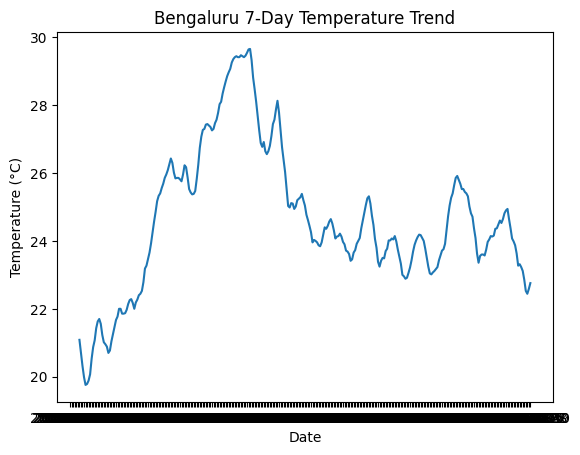

In [13]:
import matplotlib.pyplot as plt

plt.plot(bengaluru["time"], bengaluru["7_day_avg_temperature"])

plt.title("Bengaluru 7-Day Temperature Trend")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")

plt.show()

In [27]:
# Create a month column

df["time"] = pd.to_datetime(df["time"])
df["month"] = df["time"].dt.month

In [28]:
# Create Bengaluru DataFrame again

bengaluru = df[df["city"] == "Bengaluru"]

In [29]:
# Calculate monthly average temperature

monthly_temp = bengaluru.groupby("month")["temperature_2m_mean (°C)"].mean()

monthly_temp

month
1     21.025806
2     23.260714
3     26.254839
4     28.836667
5     26.280645
6     24.196667
7     24.100000
8     23.441935
9     24.686667
10    23.836667
Name: temperature_2m_mean (°C), dtype: float64

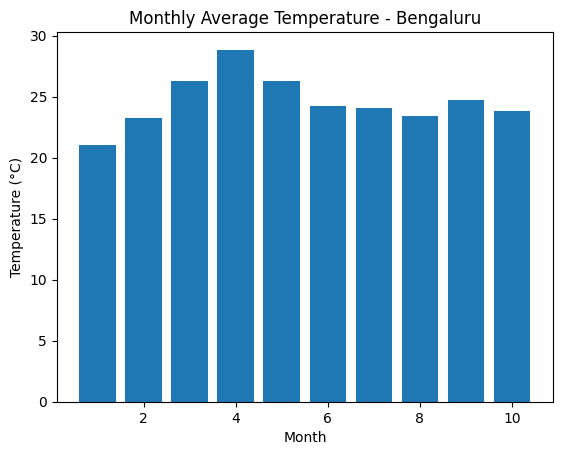

In [30]:
# Calculate monthly average temperature

import matplotlib.pyplot as plt

plt.bar(monthly_temp.index, monthly_temp.values)
plt.title("Monthly Average Temperature - Bengaluru")
plt.xlabel("Month")
plt.ylabel("Temperature (°C)")
plt.show()

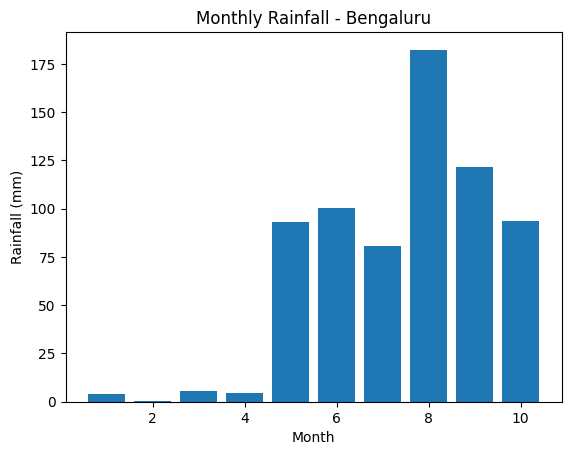

In [31]:
# Which month received the highest rainfall in Bengaluru?

monthly_rain = bengaluru.groupby("month")["precipitation_sum (mm)"].sum()

import matplotlib.pyplot as plt

plt.bar(monthly_rain.index, monthly_rain.values)

plt.title("Monthly Rainfall - Bengaluru")
plt.xlabel("Month")
plt.ylabel("Rainfall (mm)")

plt.show()

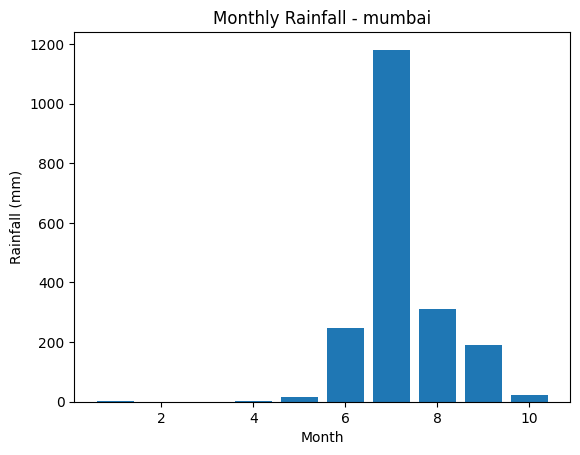

In [32]:
# Which month received the highest rainfall in Mumbai?

mumbai = df[df["city"] == "Mumbai"]

monthly_rain = mumbai.groupby("month")["precipitation_sum (mm)"].sum()

import matplotlib.pyplot as plt

plt.bar(monthly_rain.index, monthly_rain.values)

plt.title("Monthly Rainfall - mumbai")
plt.xlabel("Month")
plt.ylabel("Rainfall (mm)")

plt.show()

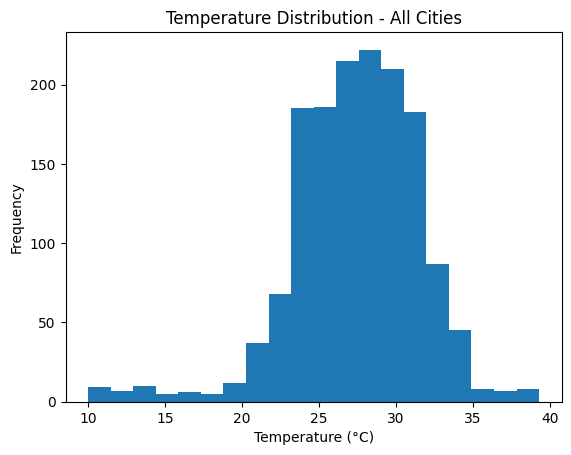

In [33]:
# How are daily mean temperatures distributed across all five cities?

import matplotlib.pyplot as plt

plt.hist(df["temperature_2m_mean (°C)"], bins=20)

plt.title("Temperature Distribution - All Cities")
plt.xlabel("Temperature (°C)")
plt.ylabel("Frequency")

plt.show()

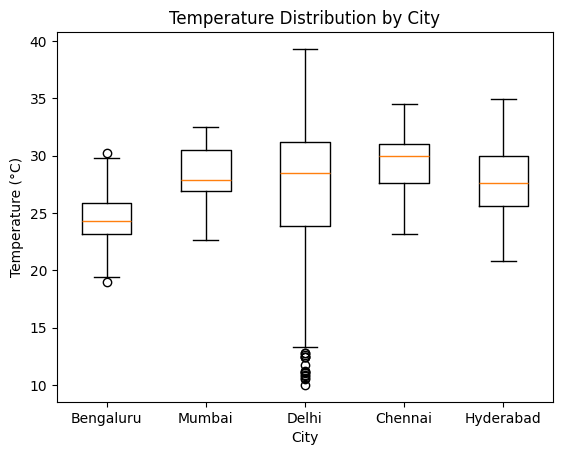

In [34]:
# How does the temperature distribution vary across the five cities?

import matplotlib.pyplot as plt

plt.boxplot([
    df[df["city"] == "Bengaluru"]["temperature_2m_mean (°C)"],
    df[df["city"] == "Mumbai"]["temperature_2m_mean (°C)"],
    df[df["city"] == "Delhi"]["temperature_2m_mean (°C)"],
    df[df["city"] == "Chennai"]["temperature_2m_mean (°C)"],
    df[df["city"] == "Hyderabad"]["temperature_2m_mean (°C)"]
])

plt.xticks([1, 2, 3, 4, 5],
           ["Bengaluru", "Mumbai", "Delhi", "Chennai", "Hyderabad"])

plt.title("Temperature Distribution by City")
plt.xlabel("City")
plt.ylabel("Temperature (°C)")

plt.show()

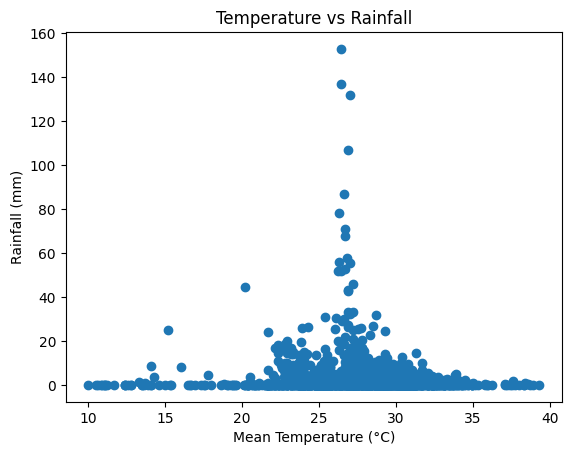

In [35]:
# Is there a relationship between daily mean temperature and rainfall across all five cities?

import matplotlib.pyplot as plt

plt.scatter(
    df["temperature_2m_mean (°C)"],
    df["precipitation_sum (mm)"]
)

plt.title("Temperature vs Rainfall")
plt.xlabel("Mean Temperature (°C)")
plt.ylabel("Rainfall (mm)")

plt.show()